# 2. Machine Learning for Regression

In [1]:
import pandas as pd
import numpy as np

## 2.2 Data preparation

In [2]:
#data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/refs/heads/master/chapter-02-car-price/data.csv'

!wget -P ../data $data 

wget: missing URL
Usage: wget [OPTION]... [URL]...

Try `wget --help' for more options.


In [3]:
df = pd.read_csv('../data/data.csv')

In [4]:
df.head(5)

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [5]:
df.columns

Index(['Make', 'Model', 'Year', 'Engine Fuel Type', 'Engine HP',
       'Engine Cylinders', 'Transmission Type', 'Driven_Wheels',
       'Number of Doors', 'Market Category', 'Vehicle Size', 'Vehicle Style',
       'highway MPG', 'city mpg', 'Popularity', 'MSRP'],
      dtype='str')

In [6]:
df.dtypes

Make                     str
Model                    str
Year                   int64
Engine Fuel Type         str
Engine HP            float64
Engine Cylinders     float64
Transmission Type        str
Driven_Wheels            str
Number of Doors      float64
Market Category          str
Vehicle Size             str
Vehicle Style            str
highway MPG            int64
city mpg               int64
Popularity             int64
MSRP                   int64
dtype: object

In [7]:
df.columns

Index(['Make', 'Model', 'Year', 'Engine Fuel Type', 'Engine HP',
       'Engine Cylinders', 'Transmission Type', 'Driven_Wheels',
       'Number of Doors', 'Market Category', 'Vehicle Size', 'Vehicle Style',
       'highway MPG', 'city mpg', 'Popularity', 'MSRP'],
      dtype='str')

In [8]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
df.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='str')

In [9]:
df.dtypes == 'object' # if not exist 'object' values use the next 'type' for the columns

make                 False
model                False
year                 False
engine_fuel_type     False
engine_hp            False
engine_cylinders     False
transmission_type    False
driven_wheels        False
number_of_doors      False
market_category      False
vehicle_size         False
vehicle_style        False
highway_mpg          False
city_mpg             False
popularity           False
msrp                 False
dtype: bool

In [10]:
df.dtypes[df.dtypes == 'str']

make                 str
model                str
engine_fuel_type     str
transmission_type    str
driven_wheels        str
market_category      str
vehicle_size         str
vehicle_style        str
dtype: object

In [11]:
df.dtypes[df.dtypes == 'str'].index

Index(['make', 'model', 'engine_fuel_type', 'transmission_type',
       'driven_wheels', 'market_category', 'vehicle_size', 'vehicle_style'],
      dtype='str')

In [12]:
strings = list(df.dtypes[df.dtypes == 'str'].index)
strings

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

In [13]:
for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')

In [14]:
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


In [15]:
df.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

## 2.3 Exploratory data analysis

In [16]:
df

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11909,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,46120
11910,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,56670
11911,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,50620
11912,acura,zdx,2013,premium_unleaded_(recommended),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,50920


In [17]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print("Unique elements in the object : ", df[col].nunique())
    print("-" * 40,"\n")

make
<StringArray>
['bmw', 'audi', 'fiat', 'mercedes-benz', 'chrysler']
Length: 5, dtype: str
Unique elements in the object :  48
---------------------------------------- 

model
<StringArray>
['1_series_m', '1_series', '100', '124_spider', '190-class']
Length: 5, dtype: str
Unique elements in the object :  914
---------------------------------------- 

year
[2011 2012 2013 1992 1993]
Unique elements in the object :  28
---------------------------------------- 

engine_fuel_type
<StringArray>
[   'premium_unleaded_(required)',               'regular_unleaded',
 'premium_unleaded_(recommended)',       'flex-fuel_(unleaded/e85)',
                         'diesel']
Length: 5, dtype: str
Unique elements in the object :  10
---------------------------------------- 

engine_hp
[335. 300. 230. 320. 172.]
Unique elements in the object :  356
---------------------------------------- 

engine_cylinders
[ 6.  4.  5.  8. 12.]
Unique elements in the object :  9
-------------------------------------

Distribution of price


In [18]:
import seaborn as sbn
from matplotlib import pyplot as plt
%matplotlib inline

The 1e6 on the x axis is scientific notation: 10 to the power of 6, that is, one million. And what we see is that a lot of prices are pretty cheap — most of the cars are concentrated on the left. Then there are very few cars that are super expensive: maybe one car costs 2 million, one costs 1.5 million, and a few cost around a million. There are not so many of them, but they have huge values.

This kind of distribution is called a long-tail distribution: most of the data sits in one place, and a shallow tail stretches far to the right. Long-tail distributions are very common for prices: most things are cheap because that's what the general public can afford, but there are a few super-expensive items for the few people who can buy them.

To see the shape better, we zoom in on prices below 100,000:

<Axes: xlabel='msrp', ylabel='Count'>

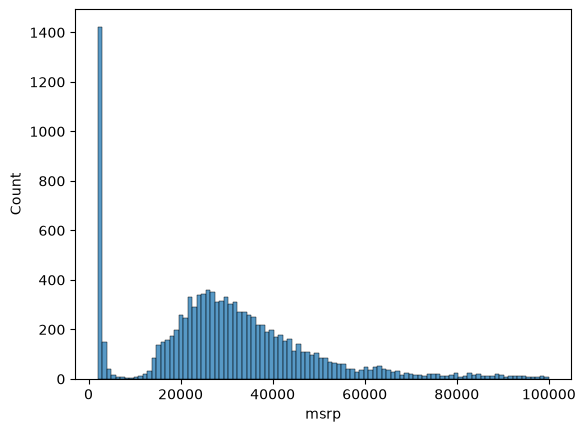

In [19]:
sbn.histplot(df.msrp[df.msrp < 1e5], bins=100)

This is the left part of the previous histogram, and it is much easier to read. There is a strange peak of cars that cost 1,000 — probably the minimal price possible to put on the platform, which is why a bunch of cars cost exactly that. Then the number of cars slowly grows up to around 25,000 — about 700 cars cost that much — and after that it goes down as the price grows. Except for that peak at 1,000, this is a pretty reasonable distribution to expect for prices.

### Removing the long tail with a logarithm
While this distribution is not unexpected, it is not really good for machine learning: <u>the long tail will confuse the model</u> and screw things up. We want to get rid of it, and the usual trick is to apply the logarithm to the price.

The logarithm compresses large values. For large numbers, the value of the logarithm is not that large: going from 10 to 1,000 is a big jump, but the increase between their logarithms is not that high. So the logarithm takes very high values and makes them lower.

There is one problem with the plain logarithm: the logarithm of zero doesn't exist. If there is a zero in the data, numpy complains — it returns negative infinity and prints a warning:

```python
np.log([0 + 1, 1 + 1, 10 + 1, 1000 + 1, 100000 + 1])
```
```bash
RuntimeWarning: divide by zero encountered in log
array([-inf, 0., 2.30258509, 6.90775528, 11.51292546])
```
In our case prices are always 1,000 or more, so this can't happen. Still, it's pretty common to add one to all values before taking the logarithm, just to be safe. NumPy has a shortcut for exactly this: log1p, where "1p" stands for "plus one". It adds one to every value and then takes the logarithm:

In [20]:
np.log1p([0, 1, 10, 1000, 100000]) #'logarithm plus one'

array([ 0.        ,  0.69314718,  2.39789527,  6.90875478, 11.51293546])

In [21]:
prices_logs = np.log1p(df.msrp)
prices_logs

0        10.739349
1        10.612779
2        10.500977
3        10.290483
4        10.448744
           ...    
11909    10.739024
11910    10.945018
11911    10.832122
11912    10.838031
11913    10.274913
Name: msrp, Length: 11914, dtype: float64

Now, we gonna draw it with the prices

<Axes: xlabel='msrp', ylabel='Count'>

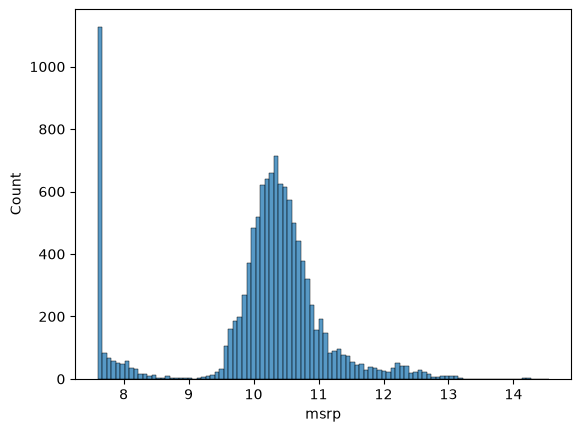

In [22]:
sbn.histplot(prices_logs, bins=100)

### Missing values

One more thing before we finish: missing values. Some values in the dataset were not recorded. When pandas doesn't have a value, it shows it as NaN — not a number. We saw this when looking at the data: some cars have NaN in the number of doors column.

To count how many missing values there are, we use isnull(): for every cell it says whether the value in this cell is missing or not. In this form it is not super useful, so we follow it with sum(), which sums across every column and tells us the number of missing values in each:

In [23]:
df.isnull()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11909,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
11910,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
11911,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
11912,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [24]:
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

For quite a few cars we don't know the fuel type, the market category, the
horsepower or the number of cylinders. We need to keep this in mind: before
training the model, we will need to do something with these missing values.

To summarize: we looked at the different values in every column, then looked
at the distribution of the price, saw that it has a long tail and removed
its effect with a logarithm transformation, and finally checked the missing
values. In the next lesson we set up the validation framework, because
before training a model we need to make sure we can validate it — see
<u>setting up the validation framework</u>

### Notes
<details>
<summary>Other annotations in other frameworks</summary>

**Pandas attributes and methods:** 

* `df[col].unique()` -> return a list of unique values in the series 
* `df[col].nunique()` -> return the number of unique values in the series 
* `df.isnull().sum()` -> return the number of null values in the dataframe 

**Matplotlib and seaborn methods:**

* `%matplotlib inline` -> assure that plots are displayed in jupyter notebook's cells
* `sns.histplot()` -> show the histogram of a series 
   
**Numpy methods:**
* `np.log1p()` -> apply log transformation to a variable, after adding one to each input value.

Long-tail distributions usually confuse the ML models, so the recommendation is to transform the target variable distribution to a normal one whenever possible. 
<details/>

## 2.4  Setting up the validation framework
Let's draw it

In [25]:
n = len(df)

n_val = int(n * 0.2) # %20
n_test = int(n * 0.2) # %20
n_train = int(n * 0.6) # %60


In [26]:
n, n_val + n_test + n_train

(11914, 11912)

The result is close to the total, that the reason use the complete value with an operation. This is because, the round up of the value operation with `int`

In [27]:
n_val = int(n * 0.2) # %20
n_test = int(n * 0.2) # %20
n_train = n - n_val - n_test

In [28]:
n, n_val + n_test + n_train

(11914, 11914)

In [29]:
n_val , n_test , n_train

(2382, 2382, 7150)

## Taking a part of the dataframe with iloc

Now we know the sizes, and we need to take a part of the dataframe of that
size. For that we use `iloc`, which we saw in the introduction to pandas. We
usually give it a list of indices, but it also accepts ranges. To get the first
ten records:

In [30]:
df.iloc[:10]

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500
5,bmw,1_series,2012,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,31200
6,bmw,1_series,2012,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,26,17,3916,44100
7,bmw,1_series,2012,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,39300
8,bmw,1_series,2012,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,36900
9,bmw,1_series,2013,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,27,18,3916,37200


This is from the beginning till 10, not inclusive, so records 0 to 9. The same
way `df.iloc[10:20]` takes records from 10 to 19, and `df.iloc[10:]` takes
everything from 10 till the end.

So the simplest thing we can do is cut the dataframe sequentially:

In [31]:
df_val = df.iloc[:n_val]
df_test = df.iloc[n_val:n_val+n_test]
df_train = df.iloc[n_val+n_test:]

In [32]:
df_val

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2377,porsche,cayenne,2016,premium_unleaded_(required),570.0,8.0,automatic,all_wheel_drive,4.0,"crossover,luxury,high-performance",midsize,4dr_suv,21,14,1715,157300
2378,porsche,cayenne,2016,diesel,240.0,6.0,automatic,all_wheel_drive,4.0,"crossover,luxury,diesel",midsize,4dr_suv,29,20,1715,62300
2379,porsche,cayenne,2017,premium_unleaded_(required),520.0,8.0,automatic,all_wheel_drive,4.0,"crossover,luxury,performance",midsize,4dr_suv,21,14,1715,116500
2380,porsche,cayenne,2017,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,luxury",midsize,4dr_suv,24,18,1715,59600


There is a problem here, though: the split is sequential. In our dataset the cars are ordered by make, so validation now contains all the BMWs at the beginning and all the Porsches at the end, and there are no BMWs in train at all:

We see that there is some order in this dataset, and we need to break it. In general it is always a good idea to shuffle the data: if there is some accidental order in it, we want to make sure it does not affect the split.

## Shuffling the records
Here is the idea. In `iloc` we can pass an arbitrary sequence of numbers, and
it will return the rows in that order. So we can take the numbers from 0 to
n-1, reshuffle them, and then take the first 20% of the shuffled numbers for
validation, the next 20% for test, and the rest for train:


To generate the sequence of numbers we use `np.arange` from NumPy, and to
shuffle it we use `np.random.shuffle`:

In [33]:
idx = np.arange(n)
np.random.shuffle(idx)

In [34]:
idx

array([ 4276,  1489, 10244, ...,  9809,  2439,  1718], shape=(11914,))

Now we index the dataframe with the shuffled numbers instead of the sequential
ranges:


In [35]:
df_train = df.iloc[idx[:n_train]] # 60 % (0 - 60)
df_val = df.iloc[idx[n_train:n_train+n_val]] # 20 % (60 - 20)
df_test = df.iloc[idx[n_train+n_val:]] # 20 % (80 - 20)

In [36]:
df.iloc[idx[:10]] # suffle data

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
4276,infiniti,ex35,2009,premium_unleaded_(recommended),297.0,6.0,automatic,rear_wheel_drive,4.0,"crossover,luxury",midsize,4dr_suv,24,17,190,33800
1489,cadillac,ats_coupe,2015,flex-fuel_(unleaded/e85),321.0,6.0,automatic,all_wheel_drive,2.0,"flex_fuel,luxury,high-performance",compact,coupe,26,18,1624,50165
10244,toyota,tacoma,2017,regular_unleaded,278.0,6.0,automatic,rear_wheel_drive,4.0,NaN,compact,crew_cab_pickup,24,19,2031,32240
8300,land_rover,range_rover,2014,flex-fuel_(premium_unleaded_required/e85),510.0,8.0,automatic,four_wheel_drive,4.0,"flex_fuel,luxury,high-performance",large,4dr_suv,19,13,258,100100
2953,toyota,corolla,2017,regular_unleaded,140.0,4.0,automatic,front_wheel_drive,4.0,NaN,compact,sedan,40,30,2031,19335
2821,plymouth,colt,1992,regular_unleaded,113.0,4.0,manual,front_wheel_drive,4.0,NaN,compact,wagon,26,21,535,2000
10015,dodge,stratus,2005,regular_unleaded,200.0,6.0,automatic,front_wheel_drive,4.0,performance,midsize,sedan,25,19,1851,23335
10348,gmc,terrain,2016,regular_unleaded,182.0,4.0,automatic,front_wheel_drive,4.0,crossover,compact,4dr_suv,32,22,549,28300
11110,volvo,v50,2009,premium_unleaded_(recommended),227.0,5.0,automatic,all_wheel_drive,4.0,luxury,compact,wagon,26,18,870,35500
1834,volkswagen,beetle_convertible,2015,diesel,150.0,4.0,manual,front_wheel_drive,2.0,diesel,compact,convertible,40,30,873,29675


In [37]:
df_train.head(10)

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
4276,infiniti,ex35,2009,premium_unleaded_(recommended),297.0,6.0,automatic,rear_wheel_drive,4.0,"crossover,luxury",midsize,4dr_suv,24,17,190,33800
1489,cadillac,ats_coupe,2015,flex-fuel_(unleaded/e85),321.0,6.0,automatic,all_wheel_drive,2.0,"flex_fuel,luxury,high-performance",compact,coupe,26,18,1624,50165
10244,toyota,tacoma,2017,regular_unleaded,278.0,6.0,automatic,rear_wheel_drive,4.0,NaN,compact,crew_cab_pickup,24,19,2031,32240
8300,land_rover,range_rover,2014,flex-fuel_(premium_unleaded_required/e85),510.0,8.0,automatic,four_wheel_drive,4.0,"flex_fuel,luxury,high-performance",large,4dr_suv,19,13,258,100100
2953,toyota,corolla,2017,regular_unleaded,140.0,4.0,automatic,front_wheel_drive,4.0,NaN,compact,sedan,40,30,2031,19335
2821,plymouth,colt,1992,regular_unleaded,113.0,4.0,manual,front_wheel_drive,4.0,NaN,compact,wagon,26,21,535,2000
10015,dodge,stratus,2005,regular_unleaded,200.0,6.0,automatic,front_wheel_drive,4.0,performance,midsize,sedan,25,19,1851,23335
10348,gmc,terrain,2016,regular_unleaded,182.0,4.0,automatic,front_wheel_drive,4.0,crossover,compact,4dr_suv,32,22,549,28300
11110,volvo,v50,2009,premium_unleaded_(recommended),227.0,5.0,automatic,all_wheel_drive,4.0,luxury,compact,wagon,26,18,870,35500
1834,volkswagen,beetle_convertible,2015,diesel,150.0,4.0,manual,front_wheel_drive,2.0,diesel,compact,convertible,40,30,873,29675


There is one more problem with this code: when you run it on your computer, you
will get different records - your first car will not be a Porsche or a GMC, but
something else. To make the results reproducible, we set a random seed before
shuffling. We talked about it in the introduction to NumPy:


In [38]:
np.random.seed(2)

idx = np.arange(n)
np.random.shuffle(idx)

In [39]:
df_train = df.iloc[idx[:n_train]] # 60 % (0 - 60)
df_val = df.iloc[idx[n_train:n_train+n_val]] # 20 % (60 - 20)
df_test = df.iloc[idx[n_train+n_val:]] # 20 % (80 - 20)

In [40]:
df_train.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
2735,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,14410
6720,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,19685
5878,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,19795
11190,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,2000
4554,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,56260


With the seed set to 2, the first record in train is a ``chevrolet``, and if you
have the same version of NumPy, you will get exactly the same subset on your
computer.


### Resetting the index
Let's check the lengths of the three dataframes:


In [41]:
len(df_train), len(df_val), len(df_test)

(7150, 2382, 2382)

Looking at `df_train`, we see that the index now contains the original row
numbers - 2735, 6720 and so on, in random order. Sometimes it is inconvenient:
we don't really need to know what the original index of each record was. So we
reset the index and reassign the result back to the dataframe. We pass
`drop=True` because we don't need the old index as a column:

In [42]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

Now the index goes from 0 to 7149 again.


### Preparing y and removing msrp
We need to turn it, our `df_train`, into log transformation for the feature matrix X.


In [43]:
df_train.msrp

0        14410
1        19685
2        19795
3         2000
4        56260
         ...  
7145     54900
7146     29215
7147     34675
7148    303300
7149     37820
Name: msrp, Length: 7150, dtype: int64

The target y comes from the `msrp` column, and we already know that we need to apply the log1p
transformation to it because of the long tail in its distribution. Instead of
keeping a pandas series, we immediately take its values with `.values` to get a
NumPy array - we don't need the indexes and other pandas things for y:

In [44]:
np.log1p(df_train.msrp)

0        9.575747
1        9.887663
2        9.893235
3        7.601402
4       10.937757
          ...    
7145    10.913287
7146    10.282472
7147    10.453803
7148    12.622481
7149    10.540620
Name: msrp, Length: 7150, dtype: float64

In [45]:
y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

The last thing we need to do is remove `msrp` from the dataframes, for which we
use the `del` operator:

In [46]:
del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

We delete it because we might accidentally use it. If the price gets into the
features, we will use the price to predict the price - and of course the model
will be perfect. Then we might spend a lot of time figuring out what is wrong.
This happened to me many times, so after splitting the data I always take the
target out into a separate variable and delete it from the dataframe
completely.


## Linear Regression

### The formula for one car

Linear regression is a model for solving regression problems. Remember from
the introduction: there is regression, there is classification and there is
ranking. Regression means predicting numbers, and the output of this model is a
number - in our case, the price of a car.

You probably remember this formula from the introduction lesson:

```text
g(X) ≈ y
```

Here g is our model, X is the feature matrix and y is our target - the price.
The model g will be linear regression.

Before we go to the matrix form, let's simplify and look at one observation
instead of the entire feature matrix. One observation is one car, and this is
its price:

A car can be a row in our feature matrix, so we can think of it as a vector
with n elements: the first feature is x<sub>i1</sub>, then x<sub>i2</sub>, and
so on until x<sub>in</sub>. We want a function that takes all these features
and produces something close to the price:

```text
g(xi) ≈ yi
```

In [47]:
df_train.iloc[10]

make                                 rolls-royce
model                     phantom_drophead_coupe
year                                        2015
engine_fuel_type     premium_unleaded_(required)
engine_hp                                  453.0
engine_cylinders                            12.0
transmission_type                      automatic
driven_wheels                   rear_wheel_drive
number_of_doors                              2.0
market_category        exotic,luxury,performance
vehicle_size                               large
vehicle_style                        convertible
highway_mpg                                   19
city_mpg                                      11
popularity                                    86
Name: 10, dtype: object

Let's take an example from the training dataset - remember, we don't look at
validation or test here, only at training. Let's take row number 10. It is a
Rolls-Royce Phantom Drophead Coupe manufactured in 2015, and it has a lot of
characteristics. We take just three of them: engine horsepower, city miles per
gallon and popularity:


So for this car the feature vector is:


In [65]:
xi = [df_train.iloc[10]['engine_hp'], df_train.iloc[10]['city_mpg'], df_train.iloc[10]['popularity']]
xi

[np.float64(453.0), np.int64(11), np.int64(86)]

Here i is 10, and the features are engine horsepower (453), miles per gallon in
the city (11) and popularity (86). Popularity is the number of times people
mention this car on Twitter. Now we need a function that takes this xi and
produces a prediction for this car.


### The linear regression formula

We need to combine these values in a way that gives us something close to the
price. The formula for linear regression is:

$$g(x_i) = w_0 + w_1 \cdot x_{i1} + w_2 \cdot x_{i2} + w_3 \cdot x_{i3}$$

First we have the bias term w<sub>0</sub> - this is the prediction we make
without knowing anything about the car. But we do know something, so each
feature is multiplied by its weight: horsepower gets weight w<sub>1</sub>,
miles per gallon gets w<sub>2</sub>, popularity gets w<sub>3</sub>.

The part with the features is a sum, so we can write the formula more
compactly. Because we already use i for the car, we use j for the features, and
it goes from 1 to n (in our example, 3):

$$g(x_i) = w_0 + \sum_{j=1}^{n} w_j \cdot x_{ij}$$

Let's implement this. We have the feature vector xi, the bias term w0, and a
vector w with a weight for each feature:

In [69]:
w0 = 7.17
w = [0.01, 0.04, 0.002]

We will talk about where these weights come from later - for now, we came up
with them ourselves. The function starts the prediction at w0 and, for every
feature, adds the feature multiplied by its weight:

In [70]:
def linear_regression(xi): # IMPLEMENT
    n = len(xi)

    pred = w0

    for j in range(n):
        pred = pred + w[j] * xi[j]
    return pred

The formula says the sum goes from 1 to n, but in Python indexes start at 0,
so our loop goes from 0 to n-1. That's the whole implementation - it simply
adds up w<sub>j</sub> times x<sub>ij</sub> for every element of the feature
vector.

### What the prediction is made of

Let's apply it to our car:

In [71]:
linear_regression(xi)

np.float64(12.312)

To make sense of this number, let's look at the parts it is made of:

```text
7.17 + 453·0.01 + 11·0.04 + 86·0.002 = 12.312
```

- We start with the bias term, 7.17. This is what we predict for an average
  car if we don't know anything about it.
- Then we know the car has 453 horsepower. Each horsepower adds 0.01 to the
  prediction: if the car had only one horsepower, the price would be higher by
  0.01, and for 100 horsepower it's higher by 1. The more horsepower the engine
  has, the more expensive the car becomes - that's logical.
- The next feature is miles per gallon in the city, with weight 0.04. The more
  fuel the car consumes in the city, the more expensive it is. This can make
  sense: cars that consume more fuel are probably fancier.
- The last one is popularity, the number of mentions on Twitter, with a pretty
  low weight of 0.002. It doesn't seem to affect the price much: a lot of
  people would need to mention a car for this term to matter.


### From log price back to dollars

The prediction 12.312 is not the price in dollars. Remember that we applied the
log1p transformation to y because of the long tail in the price distribution,
so our model predicts the logarithm of the price. To undo the logarithm we
need the exponent. In NumPy there is a function for that:

In [72]:
np.exp(12.312) -1

np.float64(222347.2221101062)

In [ ]:
np.expm1(12.312) # `exp(x) minus 1` | exp(x) - 1

np.float64(222347.2221101062)

So our prediction for this car is about 222,000 dollars. And there is a
shortcut: `np.expm1` is the inverse of `np.log1p` - apply one after the other
and you are back where you started:

In [74]:
np.log1p(222347.2221101062)

np.float64(12.312)

That's linear regression for one car: we implemented the formula on a small
feature vector of size three. In the next lesson we generalize it to all the
cars at once - the [vector form]

<details>
<summary>Notes</summary>

Model for solving regression tasks, in which the objective is to adjust a line for the data and make predictions on new values. The input of this model is the **feature matrix** `X` and a `y` **vector of predictions** is obtained, trying to be as close as possible to the **actual** `y` values. The linear regression formula is the sum of the bias term \( $w_0$ \), which refers to the predictions if there is no information, and each of the feature values times their corresponding weights as \( $x_{i1} \cdot w_1 + x_{i2} \cdot w_2 + ... + x_{in} \cdot w_n$ \).

So the simple linear regression formula looks like:

$g(x_i) = w_0 + x_{i1} \cdot w_1 + x_{i2} \cdot w_2 + ... + x_{in} \cdot w_n$.

And that can be further simplified as:

$g(x_i) = w_0 + \displaystyle\sum_{j=1}^{n} w_j \cdot x_{ij}$

Here is a simple implementation of Linear Regression in python:

~~~~python
w0 = 7.1
def linear_regression(xi):
    
    n = len(xi)
    
    pred = w0
    w = [0.01, 0.04, 0.002]
    for j in range(n):
        pred = pred + w[j] * xi[j]
    return pred
~~~~
        

If we look at the $\displaystyle\sum_{j=1}^{n} w_j \cdot x_{ij}$ part in the above equation, we know that this is nothing else but a vector-vector multiplication. Hence, we can rewrite the equation as $g(x_i) = w_0 + x_i^T \cdot w$

We need to assure that the result is shown on the untransformed scale by using the inverse function `exp()`. 
</details>

## The dot product

Remember where we are. g is our model - linear regression, X is the feature
matrix (the training data) and y is the target, the price:

$$
\underbrace{g}_{\substack{\text{model} \\ \textbf{Linear Regression}}}
\left(
\underbrace{X}_{\substack{\text{feature matrix} \\ \textbf{(TRAIN)}}}
\right)
\approx
\underbrace{y}_{\substack{\text{target} \\ \textbf{PRICE}}}
$$


Let's again write the formula for a single car first. We have the bias term and
then a sum that goes from 1 to n, where we multiply each feature with its
weight:

$$g(x_i) = w_0 + \sum_{j=1}^{n} x_{ij} \cdot w_j$$

If you look at the sum, you can see that it is nothing else but a dot product -
a vector-vector multiplication. We talked about dot products in the introduction
to NumPy, and using that notation we can rewrite the formula slightly
differently: we take the vector x<sub>i</sub>, transpose it, and multiply it
with the vector of weights:

$$g(x_i) = w_0 + x_i^T w$$

$$
\begin{aligned}
g(x_i) &= w_0 + \boxed{\sum_{j=1}^{n} x_{ij} \cdot w_j} = \\[6pt]
       &= w_0 + x_i^{T} w
\end{aligned}
$$

This notation is more compact, so let's implement it. We already have the
`linear_regression` function; let's first extract the sum into a function of
its own. It is the same vector-vector multiplication we implemented before:
start the result at zero and, for each element, multiply the pair and add it to
the result:


In [ ]:
def dot(xi, w):
    n = len(xi)

    res = 0.0

    for j in range(n):
        res = res + xi[j] * w[j]

    return res

Now the linear regression function becomes short - it just adds the bias term
to the dot product between the features and the weights:

In [76]:
def linear_regression(xi):
    return w0 + dot(xi, w)

### The fictional feature

We can make it even shorter. The bias term w0 is kind of hanging out there all
alone, without a feature. Let's bring it into the dot product: we imagine that
there is one extra feature of our car, x<sub>i0</sub>, and this feature is
always 1.

Then the vector of weights becomes w0, w1, w2 and so on up to wn - it is an
n+1 dimensional vector now. And the vector of features becomes
x<sub>i0</sub>, x<sub>i1</sub>, x<sub>i2</sub> and so on, where
x<sub>i0</sub> is 1:


$$
W = \underbrace{\begin{bmatrix} w_0 & \overbrace{w_1 \;\; w_2 \;\; \cdots \;\; w_n}^{\text{feature weights}} \end{bmatrix}}_{n+1 \text{ dim}}
$$

$$
X_i = \begin{bmatrix} \color{#808080}{1} & x_{i1} & x_{i2} & \cdots & x_{in} \end{bmatrix}
\qquad (x_{i0} = 1)
$$

$$
\color{#808080}{W^{T} X_i = X_i^{T} W =}
$$

Why does this work? When we do the dot product, w0 gets multiplied by 1, so it
simply stays there, and the rest is the same dot product as before. The result
is equivalent to what we had - which means we can use the dot product notation
for the entire linear regression.

In code, in Python, adding two lists with `+` creates a new list and prepends
the first one at the beginning - exactly what we need:

In [77]:
w_new = [w0] + w

In [78]:
w_new

[7.17, 0.01, 0.04, 0.002]

We do the same with the features: prepend 1 to xi, and then take the dot
product of the two new vectors:

In [79]:
def linear_regression(xi):
    xi = [1] + xi
    return dot(xi, w_new)

The result should be the same as before:

In [80]:
linear_regression(xi)

np.float64(12.312)

And it is - the same 12.312 we got in the previous lesson.

### Linear regression for all cars

Now let's go back to thinking about all the examples, not just one. We have
the matrix X. Because of the fictional feature, each row of this matrix starts
with 1, followed by the features of that car: row one is car one, row two is
car two, and so on until row m.

$$
X^{\,m \times (n+1)}
=
\begin{matrix}
1 \\ 2 \\ 3 \\ \vdots \\ m
\end{matrix}
\begin{bmatrix}
1 & x_{11} & \cdots & x_{1n} \\
1 & x_{21} & \cdots & x_{2n} \\
1 & \vdots & \ddots & \vdots \\
1 & x_{m1} & \cdots & x_{mn}
\end{bmatrix}
\qquad
W =
\begin{bmatrix}
w_0 \\ w_1 \\ \vdots \\ w_n
\end{bmatrix}
$$

For us X has m rows and n+1 columns. What we need to do is take each row of
this matrix, do the dot product of that row with the vector of weights w, and
that gives us the prediction for that car. Doing this for all the rows - all
the cars we have in the dataset - gives us the vector of predictions y.

You can probably recognize by now that this looks very similar to
matrix-matrix multiplication. In fact, it is matrix-vector multiplication: to
apply linear regression, we take the matrix X and multiply it with the vector
w:

$$Xw \approx y$$

Let's implement it. We take three cars and prepend 1 to each feature vector,
then put them together into a matrix - a list of lists - and turn it into a
two-dimensional NumPy array:

In [86]:
x1  = [1, 148, 24, 1385]
x2  = [1, 132, 25, 2031]
x10 = [1, 453, 11, 86]

X = [x1, x2, x10]
X = np.array(X)

In [87]:
X

array([[   1,  148,   24, 1385],
       [   1,  132,   25, 2031],
       [   1,  453,   11,   86]])

The weights vector is the same w_new from before:

In [88]:
w0 = 7.17
w = [0.01, 0.04, 0.002]
w_new = [w0] + w

And now all we need to do is multiply this matrix with this vector. NumPy arrays have a dot method for that:



In [89]:
def linear_regression(X):
    return X.dot(w_new)

In [90]:
linear_regression(X)

array([12.38 , 13.552, 12.312])

For each of the three cars we get a prediction - the price for that car:

So this is linear regression. To summarize how we got here: we started with a for loop for one car, recognized that it is a dot product between the vector of features and the vector of weights, made it even shorter by adding the fictional feature - the virtual 1 - to the feature vector, and finally generalized it to a complete feature matrix, where linear regression is nothing else but a matrix-vector multiplication.

You may have been wondering where the weights come from - how do we set the values for them? That is what we will talk about in the next lesson.



### Notes

<details>
The formula of linear regression can be synthesized with the dot product between features and weights. The feature vector includes the *bias* term with an *x* value of one, such as $w_{0}^{x_{i0}},\ where\ x_{i0} = 1\ for\ w_0$.

When all the records are included, the linear regression can be calculated with the dot product between ***feature matrix*** and ***vector of weights***, obtaining the `y` vector of predictions. 
</details>

## Training linear regression: Normal equation

### Solving for the weights

We have the feature matrix `X`, and we want the predictions `g(X) = Xw`
to be close to the actual target values `y`:

```text
Xw ≈ y
```

Ideally, `Xw` equals `y` exactly, and we can try to solve this system
for `w`.

Suppose for a moment that `X` is invertible: there exists a matrix
`X⁻¹` such that `X⁻¹X` is the identity matrix `I`. Then we can multiply
both sides of the equation by `X⁻¹`:

```text
X⁻¹Xw = X⁻¹y
   Iw = X⁻¹y
    w = X⁻¹y
```

$$
\underbrace{\cancel{X^{-1} X}}_{I} \, \boxed{W} = X^{-1} y
$$

$$
W = X^{-1} y
$$

The inverse "cancels" `X`, and we get the weights directly.

There is a problem, however. `X` is a rectangular matrix: it has `m`
rows (one per car) and `n+1` columns (one per feature, plus the bias
term). In our dataset `m` is much larger than `n+1`, so the matrix is
definitely not square - and only square matrices can have an inverse.
The solution to this system simply doesn't exist.

## The Gram matrix and the normal equation
Even though the exact solution doesn't exist, we can find the closest
possible approximate solution. Multiply both sides of `Xw ≈ y` by the
transpose of `X`:

```text
XᵀXw = Xᵀy
```

The matrix `XᵀX` is called the Gram matrix:


$$
W = \Big(
\underbrace{X^{T} X}_{\substack{\text{Gram matrix} \\ (n+1) \times (n+1)}}
\Big)^{-1} X^{T} y
$$

Unlike `X`, the Gram matrix is square - it has `n+1` rows and `n+1`
columns. Square matrices usually have an inverse (not always, and we
will deal with that case later), so we can multiply both sides by
`(XᵀX)⁻¹`:

```text
(XᵀX)⁻¹XᵀXw = (XᵀX)⁻¹Xᵀy
```

On the left, `(XᵀX)⁻¹XᵀX` is the identity matrix, and `Iw = w`. That
leaves us with:

```text
w = (XᵀX)⁻¹Xᵀy
```

This is the normal equation:

$$
\underline{W} = \left(X^{T} X\right)^{-1} X^{T} y
$$

$$
I\,W = W
$$

This `w` is not the solution to the original system - that solution
doesn't exist - but it is the closest possible solution. There are
formal proofs of this claim, and they involve quite a lot of
mathematics. If you are interested, the book "Elements of Statistical
Learning" covers the derivation.

## Implementing the normal equation

Let's implement the formula step by step in NumPy. To keep things
simple, we use a small toy matrix first: nine rows and three features

In [93]:
X = [
    [148, 24, 1385],
    [132, 25, 2031],
    [453, 11, 86],
    [158, 24, 185],
    [172, 25, 201],
    [413, 11, 86],
    [38,  54, 185],
    [142, 25, 431],
    [453, 31, 86],
]
X = np.array(X)

The first step of the normal equation is the Gram matrix:

In [94]:
XTX = X.T.dot(X)

In [95]:
XTX

array([[ 696471,   44115,  718540],
       [  44115,    7146,  118803],
       [ 718540,  118803, 6359986]])

Then its inverse:


In [96]:
XTX_inv = np.linalg.inv(XTX)

In [99]:
XTX_inv

array([[ 2.35803616e-06, -1.46900642e-05,  8.00007928e-09],
       [-1.46900642e-05,  2.94487947e-04, -3.84130606e-06],
       [ 8.00007928e-09, -3.84130606e-06,  2.28083884e-07]])

We can quickly sanity-check that the inverse is correct: multiplying the Gram matrix by its inverse should give the identity matrix.

In [100]:
XTX.dot(XTX_inv).round(1)

array([[ 1.,  0.,  0.],
       [-0.,  1.,  0.],
       [ 0.,  0.,  1.]])

We see ones on the diagonal and values that are extremely close to zero
elsewhere. They are not exactly zero because floating-point numbers
have finite precision, so small round-off errors accumulate - but we
can safely treat them as zero.

Now we need a target vector `y`. Let's just come up with nine prices
on the spot:

In [101]:
y = [100, 200, 150, 250, 100, 200, 150, 250, 120]

Putting it all together, the normal equation gives us the weights:


In [102]:
w_full = XTX_inv.dot(X.T).dot(y)

In [103]:
w_full

array([0.26190562, 3.06101252, 0.03696909])

With this matrix we actually forgot one thing: the bias term. The bias
is important - it's the baseline prediction, the price of a car when we
know nothing else about it. To include it, we add a column of ones to
`X` and repeat the same steps:

In [104]:
ones = np.ones(X.shape[0])
ones

array([1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [105]:
X = np.column_stack([ones, X])
X

array([[1.000e+00, 1.480e+02, 2.400e+01, 1.385e+03],
       [1.000e+00, 1.320e+02, 2.500e+01, 2.031e+03],
       [1.000e+00, 4.530e+02, 1.100e+01, 8.600e+01],
       [1.000e+00, 1.580e+02, 2.400e+01, 1.850e+02],
       [1.000e+00, 1.720e+02, 2.500e+01, 2.010e+02],
       [1.000e+00, 4.130e+02, 1.100e+01, 8.600e+01],
       [1.000e+00, 3.800e+01, 5.400e+01, 1.850e+02],
       [1.000e+00, 1.420e+02, 2.500e+01, 4.310e+02],
       [1.000e+00, 4.530e+02, 3.100e+01, 8.600e+01]])

In [107]:
XTX = X.T.dot(X)
XTX_inv = np.linalg.inv(XTX)
w_full = XTX_inv.dot(X.T).dot(y)

In [108]:
w_full

array([ 3.00067767e+02, -2.27742529e-01, -2.57694130e+00, -2.30120640e-02])

The `np.column_stack` function stacks the vector of ones and the
feature matrix together as columns, so the ones become the first
column of `X`.


The result `w_full` contains all the weights: the first element is the
bias term, the rest are the feature weights. We can split them apart:


In [109]:
w0 = w_full[0]
w = w_full[1:]

In [110]:
w0, w

(np.float64(300.06776692555627),
 array([-0.22774253, -2.5769413 , -0.02301206]))

Note that the weights are negative here. In our earlier examples the
weights were positive: more horsepower meant a higher price. A negative
weight means the opposite - as the feature value grows, the predicted
price goes down. If this feature were the age of a car, that would make
perfect sense: the older the car, the lower the price.


Finally, let's wrap everything into a function. The function takes `X`
and `y`, adds the column of ones internally, applies the normal
equation, and returns the bias term and the weights separately:

In [ ]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [114]:
X = [
    [148, 24, 1385],
    [132, 25, 2031],
    [453, 11, 86],
    [158, 24, 185],
    [172, 25, 201],
    [413, 11, 86],
    [38,  54, 185],
    [142, 25, 431],
    [453, 31, 86],
]
X = np.array(X)
y = [100, 200, 150, 250, 100, 200, 150, 250, 120]
train_linear_regression(X=X, y=y)

(np.float64(300.06776692555627),
 array([-0.22774253, -2.5769413 , -0.02301206]))

## 2.8 Car price baseline model

In [116]:
df_train.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385
1,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031
2,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640
3,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873
4,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657


In [117]:
df_train.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
dtype: object

## Baseline model for car price prediction project

In the previous unit we implemented `train_linear_regression`, the
function that finds the weights of a linear regression model. Now we
finally use it on the car price data to build our first model: a
baseline. It is deliberately simple - only the numerical features -
and its quality is the reference point we will try to improve on.

## Selecting the base features

First, let's remind ourselves which columns the training dataframe
has:

In [118]:
df_train.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity'],
      dtype='str')

We put these five column names in a list:

In [119]:
base = ['engine_hp', 'engine_cylinders', 'highway_mpg',
        'city_mpg', 'popularity']

To get a subset of columns from a dataframe, we select the columns with this list and take the values as a NumPy array:

In [123]:
X_train = df_train[base].values
X_train

array([[ 148.,    4.,   33.,   24., 1385.],
       [ 132.,    4.,   32.,   25., 2031.],
       [ 148.,    4.,   37.,   28.,  640.],
       ...,
       [ 285.,    6.,   22.,   17.,  549.],
       [ 563.,   12.,   21.,   13.,   86.],
       [ 200.,    4.,   31.,   22.,  873.]], shape=(7150, 5))

## Dealing with missing values
Let's try to train the model right away:

In [124]:
w0, w = train_linear_regression(X_train, y_train)

In [125]:
w0, w

(np.float64(nan), array([nan, nan, nan, nan, nan]))

The result is not what we expect: both the bias term and the weights
are `nan` - "not a number".


Something is wrong with the data. Let's check for missing values:


In [126]:
df_train[base].isnull().sum()

engine_hp           40
engine_cylinders    14
highway_mpg          0
city_mpg             0
popularity           0
dtype: int64

We see that `engine_hp` and `engine_cylinders` contain missing values.
The easiest way to deal with them is to fill them with zeros:


Filling with zeros might look strange - a car with zero horsepower
doesn't exist, and no engine has zero cylinders. To see why it still
works, look at what a missing value does in the linear regression
formula. Say we have two features, and the first one is missing:

```text
g(xi) = w0 + xi1·w1 + xi2·w2      (xi1 is missing)
     = w0 +   0·w1 + xi2·w2
     = w0 +          xi2·w2
```

When `xi1` is zero, its term `xi1 · w1` disappears, so the model
effectively ignores that feature. From a common-sense point of view,
replacing a value with the mean of that feature is often more
reasonable - we saw how to do that in the homework. But from a
practical point of view, zeros keep the process simple, and sometimes
they work just fine. For the baseline model we go with zeros.

## Training the model
Now the feature matrix has no missing values, and training finishes:

In [127]:
X_train = df_train[base].fillna(0).values
w0, w = train_linear_regression(X_train, y_train)

In [128]:
w0, w

(np.float64(7.927257388070194),
 array([ 9.70589522e-03, -1.59103494e-01,  1.43792133e-02,  1.49441072e-02,
        -9.06908672e-06]))

The bias term comes out as `w0 ≈ 7.93`. Remember that we predict the
logarithm of the price, so this is on the log scale. Together with the
five weights, this is our baseline model.

## Comparing the predictions with the actual prices

Now we can apply the trained model to the training data. We use
matrix multiplication, adding the bias term separately:

In [129]:
y_pred = w0 + X_train.dot(w)

To see how good the predictions are, let's plot them as a histogram
and compare with the histogram of the actual target values. We use the
same `histplot` function from seaborn that we used during
exploratory data analysis:

In [130]:
import seaborn as sns

<Axes: ylabel='Count'>

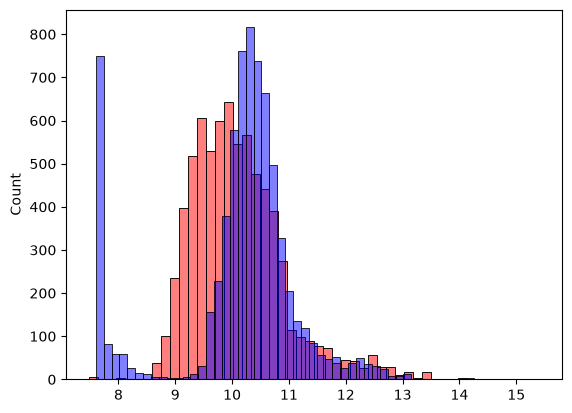

In [131]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

The `alpha` parameter controls how transparent the bars are, so both
histograms are visible in the same plot.
Looking at the chart, the distribution of predictions does not really
match the distribution of actual values: the red peak sits to the left
of the blue one, so in many cases the model predicts a value smaller
than the actual price.

Just by looking at this chart we suspect the model is not ideal, but
that is not an objective way to say it. And when we start improving the
model, we want to be sure that it indeed improved. For that we need a
single number that quantifies how good or bad the model is. That is
exactly what we will do in the next unit with RMSE.

## Notes

<details>
<summary>Notes</summary>
* In this lesson we build a baseline model and apply the `df_train` dataset to derive weights for the bias (w0) and the features (w). For this, we use the `train_linear_regression(X, y)` function from the previous lesson.
* Linear regression only applies to numerical features. Therefore, only the numerical features from `df_train` are used for the feature matrix. 
* We notice some of the features in `df_train` are `nan`. We set them to `0` for the sake of simplicity, so the model is solvable, but it will be appropriate if a non-zeo value is used as the filler (e.g. mean value of the feature).
* Once the weights are calculated, then we apply them on  $$\\\\ \large g(X) = w_0 + X \cdot w$$ to derive the predicted y vector.
* Then we plot both predicted y and the actual y on the same histogram for a visual comparison.
</details>

# 2.9 Root Mean Squared Error (RMSE)

In the previous unit we trained our first model and plotted the
predictions against the actual values. The histograms showed the
predictions are a bit off, but a chart is not an objective measure. In
this unit we learn one way of quantifying how good or bad a regression
model is: root mean squared error, or RMSE.

<details>
<summary>More details - formula & example</summary>

## The formula

RMSE starts from the difference between the prediction and the actual
value. For each observation `i`, `g(xi)` is the prediction we make and
`yi` is the actual value. We take the difference, square it, average
these squared differences over all `m` observations, and finally take
the square root:

```text
RMSE = sqrt( (1/m) · Σ (g(xi) - yi)² )
```

Let's unpack each part with a small example.

## A worked example

Imagine we have four observations. These are our predictions, and
these are the actual prices:

```text
y_pred:  10     9     11    10
y:        9     9     10.5  11.5
```

The first step is to take the difference between each prediction and
the corresponding actual value:

```text
10 - 9    =  1
 9 - 9    =  0
11 - 10.5 =  0.5
10 - 11.5 = -1.5
```

Next, we square each difference:

```text
1   → 1
0   → 0
0.5 → 0.25
-1.5 → 2.25
```

Squaring does two things: it makes negative and positive errors
comparable - otherwise they would cancel each other out - and it
penalizes larger errors more.

Then we take the average of the squared errors:

```text
(1 + 0 + 0.25 + 2.25) / 4 = 0.875
```

This is the mean squared error, MSE. For our example, the mean squared
error is 0.875:

The last step is the square root:

```text
sqrt(0.875) ≈ 0.93
```

The square root brings the error back to the same units as the target
variable. For these four observations, 0.93 is the root mean squared
error.


</details>

## Implementation

Now let's implement this in NumPy. The function takes the vector of
actual values and the vector of predictions:

In [132]:
def rmse(y, y_pred):
    error = y - y_pred
    se = error ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [133]:
rmse(y_train, y_pred)

np.float64(0.7554192603920132)

First we compute the error - the difference between `y` and `y_pred`.
Then we square it. To get the mean we don't need to sum and divide by
the number of elements: NumPy has the `mean` method, which gives us the
mean squared error directly. Finally, we take the square root and
return the result.

We can simplify the function a little by squaring the difference
inline:

In [ ]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [134]:
rmse(y_train, y_pred)

np.float64(0.7554192603920132)

The RMSE of the baseline model is about 0.76. This single number is
much easier to work with than a chart: whenever we change something -
add a feature, transform a variable, try a different model - we
recompute it. If the number goes down, the model got better.

So far we computed it on the training data. In the next unit we apply
the model to the validation set and see how it performs there.

### Notes
<details>
<summary>Notes</summary>
* In the previous lesson we found out our predictions were a bit off from the actual target values in the training dataset. We need a way to quantify how good or bad the model is. This is where RMSE can be of help.
* Root Mean Squared Error (RMSE) is a way to evaluate regression models. It measures the error associated with the model being evaluated. This numerical figure can then be used to compare models, enabling us to choose the one that gives the best predictions.

$$RMSE = \sqrt{ \frac{1}{m} \sum_{i=1}^{m} {(g(x_i) - y_i)^2}}$$

- $g(x_i)$ is the prediction
- $y_i$ is the actual value
- $m$ is the number of observations in the dataset (i.e. cars)
</details>

# 2.10 Computing RMSE on validation data
In the previous unit we implemented RMSE, the root mean squared error, and used
it to measure the quality of our baseline model. There was one problem: we
measured it on the training data - the same data the model learned from. Here we
fix that and evaluate the model the way it should be evaluated: on the
validation data.

## The validation framework

Remember how validation works. We take the dataset and split it into three
parts: the training set, the validation set and the test set. We train the model
- let's call it g - on the training part, and then we apply it to the validation
part to see how it performs on data it has never seen.


```mermaid
block-beta
    columns 5
    TRAIN["TRAIN"]:3 VAL["VAL"]:1 TEST["TEST"]:1
    space:5
    space:1 g(("g")) space:3

    TRAIN --> g
    g --> VAL
```

Two lessons ago we built our first baseline model using five numerical features
- `engine_hp`, `engine_cylinders`, `highway_mpg`, `city_mpg` and `popularity` -
and then we wrote the `rmse` function for objectively measuring the quality of
the model. But when we computed the error, we applied the model to the training
dataset, the same data we used for training.

Instead, we should apply the model to the validation data and look at the root
mean squared error there.


## Preparing the feature matrix with prepare_X
Let's take the code we wrote earlier. This is the code for training the model,
and this line is where we prepare our feature matrix X:


In [136]:
X_train = df_train[base].fillna(0).values
X_train

array([[ 148.,    4.,   33.,   24., 1385.],
       [ 132.,    4.,   32.,   25., 2031.],
       [ 148.,    4.,   37.,   28.,  640.],
       ...,
       [ 285.,    6.,   22.,   17.,  549.],
       [ 563.,   12.,   21.,   13.,   86.],
       [ 200.,    4.,   31.,   22.,  873.]], shape=(7150, 5))

A lot of things are happening here, so let's write a special function for that.
We'll call it `prepare_X`, and it takes a dataframe:

In [137]:
def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

The function does three things. First it selects the numerical columns, then it
fills the missing values, and finally it extracts the feature matrix - the NumPy
array - and returns it. We went from one line to five, but at least it is easier
to understand what is going on.

The point of this function is that we prepare the data in the same way
regardless of whether it is the training, validation or test dataset. It works
on any dataframe - that is why the argument is just `df` and not `df_train`.


## Computing the RMSE on validation data
Now we can train the model and validate it. First the training part: we prepare
the matrix from the training dataframe and train the model. Then the validation
part: we prepare the validation matrix with the same function, apply the model,
and compute the RMSE between the actual target values and our predictions:


In [138]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.7616530991301586)

The number is pretty similar to what we had on the training data. That is what
we want to see: the model behaves on unseen data about as well as on the data it
learned from.

Looking at the code, we can see the two parts clearly:


- The training part only touches the training dataset: we prepare the matrix and
  learn the weights.
- The validation part prepares the validation dataset in the same way as the
  training dataset, then applies the model learned in the previous step, and
  computes the root mean squared error for that model.

Now we have a way of evaluating the quality of our model using the root mean
squared error on the validation dataset. This also means we can check whether a
change actually improves the model - and this is what we will do next, starting
with [feature engineering](11-feature-engineering.md).

## Notes

Calculation of the RMSE on validation partition of the dataset of car price prediction. In this way, we have a metric to evaluate the model's 
performance. 

# 2.11 Feature engineering
Feature engineering is the process of creating new features from the ones we
already have. In this unit we create our first new feature - the age of a car -
and see it improve the RMSE of our model quite a bit.

$$
\begin{array}{|c|}
\hline
\textbf{Raw Car Data} \\ \hline
\text{year} \\ \hline
2008 \\
2012 \\
2016 \\ \hline
\end{array}
\;\xrightarrow{\;2017 - \text{year}\;}\;
\begin{array}{|c|}
\hline
\textbf{New Feature} \\ \hline
\text{age} \\ \hline
9 \\
5 \\
1 \\ \hline
\end{array}
\;\longrightarrow\;
\boxed{\begin{array}{c} \textbf{Model} \\ \boxed{\text{Input Matrix}} \end{array}}
$$

*Figure: Subtracting each car's year from 2017 creates the `age` feature that enters the model input matrix.*



## From year to age

Let's take a look again at our training dataset. One of the columns there is
`year`, and we know this is one of the most important variables for predicting
the price of a car: if a car is old, it is usually cheaper, and if it is new, it
is more expensive.

Instead of using the year as it is, we can compute the age of a car. For that we
need to know when this data was collected - it turns out it was collected in
2017. So "now" is 2017, and the age is simply `2017 - year`. Some of the cars
are 0 years old, some are 9, some are 26:


In [139]:
2017 - df_train.year

0        9
1        5
2        1
3       26
4        0
        ..
7145     2
7146     2
7147     2
7148     3
7149     0
Name: year, Length: 7150, dtype: int64

## Adding the age feature to prepare_X
Let's modify the `prepare_X` function we wrote in the *previous unit*. The new feature is called `age`, and
we compute it in the same way we just did, except that instead of `df_train` we
use the dataframe the function receives - it could be the training, validation
or test set.

We also need to use the new feature when building the matrix. Instead of `base`,
we create a list called `features` that contains the baseline numerical features
plus the new `age` feature:


In [140]:
def prepare_X(df):
    df['age'] = 2017 - df.year
    features = base + ['age']

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

# The function should not modify the data

When we run this function, the first line adds a new column - and if we look at
`df_train` again, we see that a new column appeared in it. We modified the
dataframe we passed in.

This is not something this function should do. As a user of this function, I
don't want it to change my data - what if it does something that cannot be
undone? It is much better if the function doesn't modify the dataframes it
receives.

The fix is simple: before doing anything, we take a copy of the dataframe and
work with that copy inside the function. The original dataframe stays unchanged
- after the function returns, we simply forget about the copy, because all we
care about at the end is `X`.

In [142]:
def prepare_X(df):
    df = df.copy()

    df['age'] = 2017 - df.year
    features = base + ['age']

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

Now `X_train` has six columns - the five base features plus `age`, which is the
last one.

## Checking the improvement

Let's validate the model with the same code as before: prepare the matrices,
train the model, apply it to the validation set and compute the RMSE:


In [143]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.5172055461058309)

The model improved, and it is quite an improvement - the RMSE went down from
0.76 to 0.51:

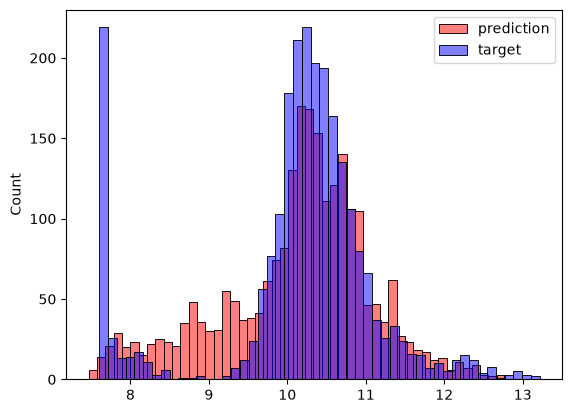

In [145]:
sns.histplot(y_pred, label='prediction', color='red', alpha=0.5, bins=50)
sns.histplot(y_val, label='target', color='blue',  alpha=0.5, bins=50)
plt.legend()

We can see that it is a big improvement by doing the same thing as previously:
plotting the predicted values and the actual values on the same histogram. Note
that now we compare against `y_val`, because we are predicting on the validation
dataset, not on the training dataset as previously.

The shapes of the two distributions are now much closer. There is still a lot of
room for improvement - for example, the model completely misses this bar here -
but in general it is doing much better.

## Notes

The feature age of the car was included in the dataset, obtained with the subtraction of the maximum year of cars and each of the years of cars. 
This new feature improved the model performance, measured with the RMSE and comparing the distributions of y target variable and predictions. 

# 2.12 Categorical variables
Categorical variables are variables that contain categories instead of numbers.
In this unit we add them to our car price model and see that one of them breaks
it completely - which is exactly the problem the next unit solves.

## Explanation

<details>
<summary>Explanation</summary>

## Variables that are categories

So far we only used numerical features. But the dataset has quite a few
categorical variables - variables that are categories. They are typically
strings: `make`, `model`, `engine_fuel_type`, `transmission_type`,
`driven_wheels` and others. If we look at the data types, all the columns of
type `object` are categorical variables.


There is one variable that looks numerical but is not: `number_of_doors`. It
contains 2, 3 and 4 - numbers - but these numbers are distinct categories of
cars: cars with two doors, cars with three doors and cars with four doors are
quite different. It just happened that the values of this variable are numbers,
and that's why pandas treats them as usual numbers.

We want to use variables like that in our model, because they could be
important. For example, cars with two doors are probably more expensive than
cars with four doors.

## Encoding categories as binary columns

ML models can only work with numbers, so we need to encode categorical
variables. The typical way of doing it: for each value of the column, we create
a separate binary column. If our column contains the values 2, 3, 4 and 2 again,
we represent it with three columns - one for each door count - and put 1 in the
column that matches the row, and 0 everywhere else:

| number_of_doors | num_doors_2 | num_doors_3 | num_doors_4 |
| --- | ---: | ---: | ---: |
| 2 | 1 | 0 | 0 |
| 3 | 0 | 1 | 0 |
| 4 | 0 | 0 | 1 |
| 2 | 1 | 0 | 0 |

One categorical column becomes multiple binary columns, and each row gets
exactly one 1.

In pandas, the comparison operator does most of the work. When we say
`df.number_of_doors == 2`, we get `True` for every car that has two doors:

```python
df_train.number_of_doors == 2
```

The result is a series of booleans, so the only thing left is to turn it into
integers - ones and zeros - with `astype(int)`.

To create the columns, we can write a loop over the values `[2, 3, 4]` and use a
string template for the name, so that each value gets its own column:

```python
for v in [2, 3, 4]:
    df_train['num_doors_%s' % v] = (df_train.number_of_doors == v).astype('int')
```

</details>

In [146]:
df_train.number_of_doors == 2

0        True
1       False
2       False
3       False
4       False
        ...  
7145     True
7146     True
7147    False
7148    False
7149    False
Name: number_of_doors, Length: 7150, dtype: bool

In [147]:
(df_train.number_of_doors == 2).astype('int')

0       1
1       0
2       0
3       0
4       0
       ..
7145    1
7146    1
7147    0
7148    0
7149    0
Name: number_of_doors, Length: 7150, dtype: int64

## Adding doors to prepare_X

Let's modify our `prepare_X` function again. We make a copy of the dataframe as
before, because we don't want to accidentally write these columns into our data.
We also make a copy of the `base` list: if we used `append` on `base` itself, we
would append `age` to it every time the function runs.

In [148]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')

    for v in [2, 3, 4]:
        df['num_doors_%s' % v] = (df.number_of_doors == v).astype('int')
        features.append('num_doors_%s' % v)

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

Now the features list contains the baseline features, then `age`, and then the
three new features: `num_doors_2`, `num_doors_3` and `num_doors_4`.


We validate the model with the same code as before:


In [149]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.5157995641503206)

It improved only slightly - the improvement is almost negligible. The number of doors feature is not that useful.

## Adding the make
But I'm pretty sure that `make` should be quite useful. If we look at the values
of this column, there are a lot of them - 48 unique makes. We can take the most
popular ones with `value_counts`:

In [150]:
df.make.value_counts().head()

make
chevrolet     1123
ford           881
volkswagen     809
toyota         746
dodge          626
Name: count, dtype: int64

The output shows the counts, and the names themselves are in the index, so we
wrap it in a list:

In [151]:
makes = list(df.make.value_counts().head().index)
makes

['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge']

This gives us the five most popular makes of cars: chevrolet, ford, volkswagen, toyota and dodge. We can include them in the same way as the number of doors - one binary column per make:

In [152]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')

    for v in [2, 3, 4]:
        df['num_doors_%s' % v] = (df.number_of_doors == v).astype('int')
        features.append('num_doors_%s' % v)
    
    for v in makes:
        df['make_%s' % v] = (df.make == v).astype('int')
        features.append('make_%s' % v)

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [153]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.5076038849555385)

We validate again, and this time the results improve by about one percent -
0.5077 instead of 0.5158. Not as drastic as when we added `age`, but quite okay.


## Doing the same for all categorical variables

We can do the same for the other categorical variables: `engine_fuel_type`,
`transmission_type`, `driven_wheels`, `market_category`, `vehicle_size` and
`vehicle_style`. I'm not adding `model` here because there are simply too many
models.

First we collect the top five most common values for each of them into a
dictionary:

In [154]:
categorical_variables = [
    'make', 'engine_fuel_type', 'transmission_type', 'driven_wheels',
    'market_category', 'vehicle_size', 'vehicle_style'
]

categories = {}

for c in categorical_variables:
    categories[c] = list(df_train[c].value_counts().head().index)

In [155]:
categories

{'make': ['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge'],
 'engine_fuel_type': ['regular_unleaded',
  'premium_unleaded_(required)',
  'premium_unleaded_(recommended)',
  'flex-fuel_(unleaded/e85)',
  'diesel'],
 'transmission_type': ['automatic',
  'manual',
  'automated_manual',
  'direct_drive',
  'unknown'],
 'driven_wheels': ['front_wheel_drive',
  'rear_wheel_drive',
  'all_wheel_drive',
  'four_wheel_drive'],
 'market_category': ['crossover',
  'flex_fuel',
  'luxury',
  'hatchback',
  'luxury,performance'],
 'vehicle_size': ['compact', 'midsize', 'large'],
 'vehicle_style': ['sedan',
  '4dr_suv',
  'coupe',
  'convertible',
  '4dr_hatchback']}

Then we take `prepare_X` and throw in all the categories. We need two loops: one
over the key-value pairs of the dictionary, and inside it another loop over the
values of each category:

In [160]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')

    for v in [2, 3, 4]:
        df['num_doors_%s' % v] = (df.number_of_doors == v).astype('int')
        features.append('num_doors_%s' % v)
    
    for c, values in categories.items():
        for v in values:
            df['%s_%s' % (c, v)] = (df[c] == v).astype('int')
            features.append('%s_%s' % (c, v))
            
    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [161]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(78.42225863248343)

## Something went wrong (?)

<details>
<summary>According to the text</summary>

We execute the same validation code again, and now the value is significantly
higher than what we had before. Before we had 0.5, and now all of a sudden it's
41:

```
41.45414769975256
```

Something went wrong. If we look at the weights that our
`train_linear_regression` function outputs, they are huge - some of them are
around 10 to the power of 15. We wanted to improve our model by adding more
variables, but we just made it worse.


In the [next unit](13-regularization.md) we will see why that happened and how
to fix it.

## Notes

Categorical variables are typically represented as strings, and pandas identifies them as object types. However, some variables that appear to be numerical may actually be categorical (e.g., the number of doors a car has). All these categorical variables need to be converted to a numerical form because ML
models can interpret only numerical features. It is possible to incorporate certain categories from a feature, not necessarily all of them. 
This transformation from categorical to numerical variables is known as One-Hot encoding. 

## Comments

This way of encoding categorical features is called "one-hot encoding".
We'll learn more about it in Session 3. 
</details>


# 2.13 Regularization

In the previous unit we added categorical variables to our model and ended up with an RMSE of 41 and huge weights. In this unit we look at why that happened and learn a technique for dealing with it: regularization.

## The inverse that doesn't always exist

Remember the formula for the normal equation we use for training our model:

```
w = (XᵀX)⁻¹ Xᵀ y
```

The problem we have is with this part: we need to take the inverse of the Gram
matrix `XᵀX`, and sometimes this inverse doesn't exist.

It usually happens when the feature matrix X has duplicate columns. Let's
quickly check it with a small matrix where the second and the third columns have
the same values:

In [162]:
X = [
    [4, 4, 4],
    [3, 5, 5],
    [5, 1, 1],
    [5, 4, 4],
    [7, 5, 5],
    [4, 5, 5],
]

When we compute the Gram matrix, we see that it also has duplicate columns - the
second and the third are the same:


When something like that happens, the inverse simply doesn't exist. In linear
algebra they say that one column is a linear combination of the other columns -
which here just means that the third column is a duplicate of the second one.

## Noisy data makes the inverse huge
This is not exactly the case for our car price problem - there we didn't see the
singular matrix error. The reason is that real data is usually not super clean.
When people record observations, they make mistakes: instead of writing 5, they
write 5.00000001.

Let's add a tiny number like that to one value in our matrix:

In [163]:
X = [
    [4, 4, 4],
    [3, 5, 5],
    [5, 1, 1],
    [5, 4, 4],
    [7, 5, 5],
    [4, 5, 5.00000001],
]

Now the columns are no longer exactly the same - they are slightly different -
so the matrix is not exactly singular anymore. It becomes at least numerically
invertible, and NumPy finds an inverse. But look at what it comes up with: the
numbers in the inverse are huge, around 10 to the power of 14.


When we use this inverse to compute the weights, the weights for the duplicated
features turn out to be very large numbers too. The weight for the unique first
feature is fine - 0.62 - but for the second and third features we get something
like 3.4 million and -3.4 million.


So whenever we have duplicates - or near-duplicates - in our feature matrix, we
get this problem.

## A smaller example

Let's illustrate all of this on a smaller matrix. This one also has a column
that is a duplicate of another one:

In [164]:
XTX = [
    [1, 2, 2],
    [2, 1, 1],
    [2, 1, 1],
]

If we try to invert it, NumPy refuses: it complains that the matrix is singular
and it cannot compute the inverse:


Now let's do the same trick as before and add a tiny bit of noise:

In [165]:
XTX = [
    [1, 2, 2],
    [2, 1, 1.0000001],
    [2, 1.0000001, 1],
]

The inverse exists now, but look at the numbers in it - around 5 million. We will fix that in a second.



## Controlling the weights with regularization

To solve this problem, we can add a small number to the diagonal of the matrix.
If we add a small number to the diagonal - say 0.01 - the inverse can still be
found, and the numbers in it are much more under control. The larger the number
we add to the diagonal, the more control we get over the weights.

This works because by adding something to the diagonal, we make sure that it is
less possible that one column is a duplicate of another.

To add a number to the diagonal, we use the identity matrix - `np.eye(3)` is the
3×3 identity matrix, which has ones on the diagonal. When we add it to our
matrix, the diagonal increases by one:

In [166]:
XTX + np.eye(3)

array([[2.       , 2.       , 2.       ],
       [2.       , 2.       , 1.0000001],
       [2.       , 1.0000001, 2.       ]])

To add only a small number, we multiply the identity matrix by that number first:

In [167]:
XTX = XTX + 0.01 * np.eye(3)

This way of controlling the weights is called regularization - the name comes
from controlling, regulating the weights so that they don't grow too much.

The number we add is actually a parameter. The larger the number on the
diagonal, the smaller the values in the inverse of `XᵀX`. How much regularization
to add becomes a parameter of our model.

## The regularized training function
With that, we can go back to our function for training linear regression and
slightly change it. We'll call it `train_linear_regression_reg`, and it gets one
more parameter - `r`, short for regularization:


In [168]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

Everything stays the same except one line: after computing the Gram matrix, we
add `r` to the main diagonal.


Let's take the code from the previous unit and replace the training function
with this new one, using `r=0.01`:


In [169]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression_reg(X_train, y_train, r=0.01)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.45652199012160566)

The result is not only much better than the 41 we got with the
non-regularized version - it is also better than what we had before adding all
the categorical variables:
```
0.4608208286209523
```

### Notes
<details>

If the feature matrix has duplicate columns (or columns that can be expressed as a linear combination of other columns), it will not have an inverse matrix. But, sometimes this error could be passed if certain values are slightly different
between duplicated columns. 

So, if we apply the normal equation with this feature matrix, the values associated with duplicated columns are very large, which decreases
the model performance. To solve this issue, one alternative is adding a small number to the diagonal of the feature matrix, which corresponds to regularization. 

This technique 
works because the addition of small values to the diagonal makes it less likely to have duplicated columns. The regularization value is a hyperparameter of the model. After applying 
regularization the model performance improved. 

## Comments
### Linear combination

I mentioned the term *linear combination* in the video, but didn't explain what it means. 
So if you're interested what it means, you can read here

* One column is a linear combination of others when you can express one column of a matrix as a sum of others columns
* The simplest example is when a column is an exact duplicate of another column
* Another example. Let's say we have 3 columns: `a`, `b`, `c`. If `c = 0.2 * a + 0.5 * b`, then `c` is a linear combination of `a` and `b`
* More formal definition: https://en.wikipedia.org/wiki/Linear_combination

### Ridge Regression
The regularization technique used (adding a factor to the diagonals of Gram Matrix) in this lesson is Ridge Regression. Further explanations are available in this [DataTalks.Club article](https://datatalks.club/blog/regularization-in-regression.html)
</details>

# Tuning the model
In the previous unit we saw that the regularization parameter r affects the quality of our model. Tuning the model means finding the best value for this parameter - and the validation set is exactly the tool for that.

## Trying different values of r

What we will do is simply try a bunch of different values for `r`: starting from
zero, then something small, gradually increasing it, and maybe even 10:

In [170]:
for r in [0.0, 0.00001, 0.0001, 0.001, 0.1, 1, 10]:
    X_train = prepare_X(df_train)
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    print(r, w0, score)

0.0 1.446434400304926e+16 78.42225863248343
1e-05 5.475459705768581 0.45651702256511534
0.0001 6.284303969329338 0.45651706492345767
0.001 6.28577307571493 0.45651750857439627
0.1 6.191208699244078 0.45656927630079813
1 5.63489666790905 0.4572204317993652
10 4.283980108960325 0.4701456932101035


We go through this list, and for every `r` we train the model and compute the
RMSE on the validation data. For each value we print the regularization
parameter itself, the bias term, and the score:

## Reading the results


What we see: for zero regularization the bias term is huge and the RMSE is huge
too - 266. That is the broken model with the duplicated columns problem. But for
even a little bit of regularization it improves immediately, and after that the
score doesn't really change that much. It starts to become a bit worse as we
increase the regularization, and when it's 10 it's even worse.

Looking at the bias term, the more regularization we add, the smaller it is. It
looks like maybe 0.001 is a good value, because the model hasn't started to
degrade in performance there, and it's not too large. To be honest, it doesn't
really matter here - it could be this one or the one next to it. We can just go
with 0.001.

## Training the final model

Let's train our model once again with the selected value:

In [171]:
r = 0.001
X_train = prepare_X(df_train)
w0, w = train_linear_regression_reg(X_train, y_train, r=r)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
score = rmse(y_val, y_pred)
score

np.float64(0.45651750857439627)

We selected the best regularization parameter, trained the model with it, and we
saw that it works on the validation set: ```0.46081585838957173```

### Notes

Tuning the model consisted of finding the best regularization hyperparameter value, using the validation partition of the dataset. The model was then trained with this regularization value. 

# 2.15 Using the model
In the previous unit we found the best regularization parameter. In this unit we train the final model, check it on the test data, and then use it the way it would be used in practice: to predict the price of a single car.

## Training the final model

Remember that we split our dataset into three parts: train, validation and
test. So far we trained the model on the training part and computed the RMSE on
the validation part. For the final model we do something different: we combine
the training and validation datasets into one - let's call it `full_train` -
train the model on all of it, and then make the final evaluation on the test
dataset.

The idea is simple: now that we have tuned all the parameters, we want to give
the model as much data as possible for training, and keep the test set untouched
for the final check. The RMSE on test shouldn't be too different from what we
saw on validation.

We have two dataframes, `df_train` and `df_val`, and we want to combine them
into one. In pandas there is a function for that - `concat`, short for
concatenate. It takes a list of dataframes and concatenates them together:



In [173]:
df_full_train = pd.concat([df_train, df_val])

If we look at the result, we see that even though there are around 9500 rows now, the index still contains the values from the validation dataframe. We can fix that by resetting the index:

In [176]:
df_full_train = df_full_train.reset_index(drop=True)
df_full_train.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385
1,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031
2,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640
3,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873
4,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657


Now everything is sequential, and we can use the `prepare_X` function to get the
feature matrix:

In [177]:
X_full_train = prepare_X(df_full_train)

We also need the target values `y`. There is a function in NumPy called
`concatenate` that does the same thing for arrays - and since arrays have no
index, we don't need to reset anything:


In [178]:
y_full_train = np.concatenate([y_train, y_val])

In [179]:
y_full_train

array([ 9.57574708,  9.887663  ,  9.89323518, ..., 11.21756062,
        9.77542688, 10.1924563 ], shape=(9532,))

Now we take the code for training the model and replace `X_train` with
`X_full_train`, `y_train` with `y_full_train`, and use the `r` we selected
earlier:

In [180]:
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)

This is our final model, and these are its weights.


In [181]:
w0, w

(np.float64(6.323060505956392),
 array([ 1.52506330e-03,  1.18188702e-01, -6.66105531e-03, -5.33413929e-03,
        -4.87603202e-05, -9.69091842e-02, -7.92620967e-01, -8.90862177e-01,
        -6.35100899e-01, -4.14339217e-02,  1.75560742e-01, -5.78066985e-04,
        -1.00563876e-01, -9.27549663e-02, -4.66859189e-01,  7.98658973e-02,
        -3.16047737e-01, -5.51981710e-01, -7.89526581e-02,  1.09383694e+00,
         9.18529400e-01,  1.14810681e+00,  2.65124265e+00,  5.08466111e-01,
         1.62970376e+00,  1.53040782e+00,  1.61758654e+00,  1.54558593e+00,
        -9.70559743e-02,  3.73062114e-02, -5.81767485e-02, -1.19357173e-02,
        -2.35940857e-02,  2.18895261e+00,  2.07458271e+00,  2.05916686e+00,
        -5.00802769e-02,  5.62184639e-02,  1.84794024e-01,  3.32646151e-01,
        -1.58817038e-01]))

## Checking the model on test data
To check the final model, we prepare the test dataset exactly in the same way as
we did the validation dataset - we just replace validation with test:

In [182]:
X_test = prepare_X(df_test)
y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)
score

np.float64(0.45177493084901227)

That is a very good sign. It means our model generalizes well: it didn't get
this score just by chance.


## Predicting the price of a car
Now we can use the model the way we actually want to use it: to predict the
price of a car. Imagine there is a car, we extract all its features, put the
feature vector into the model - and it tells us the price.

For that we can take any car from the test dataset and pretend it's a new car.
This is fine, because we didn't train our model on this data. Let's take a
Toyota Sienna:


In [183]:
car = df_test.iloc[20].to_dict()
car

{'make': 'toyota',
 'model': 'sienna',
 'year': 2015,
 'engine_fuel_type': 'regular_unleaded',
 'engine_hp': 266.0,
 'engine_cylinders': 6.0,
 'transmission_type': 'automatic',
 'driven_wheels': 'front_wheel_drive',
 'number_of_doors': 4.0,
 'market_category': nan,
 'vehicle_size': 'large',
 'vehicle_style': 'passenger_minivan',
 'highway_mpg': 25,
 'city_mpg': 18,
 'popularity': 2031}

This gives us a dictionary with all the information about the car

Usually we don't get a dataframe when we want to make a prediction. In a real life scenario it could be a website or an app where people enter the values about the car, and the website sends a request with all this information to the model - the model replies back with the price. That's why we turn the car into a dictionary: this is how such requests usually look.

Our `prepare_X` function expects a dataframe, though. So we create a small
dataframe with a single row - pandas can create a dataframe from a list of
dictionaries, and our list contains just the one car from the request:

In [184]:
df_small = pd.DataFrame([car])
X_small = prepare_X(df_small)

In [186]:
df_small

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,toyota,sienna,2015,regular_unleaded,266.0,6.0,automatic,front_wheel_drive,4.0,NaN,large,passenger_minivan,25,18,2031


Then we apply the model to this feature matrix with one row:



In [185]:
y_pred = w0 + X_small.dot(w)
y_pred = y_pred[0]
y_pred

np.float64(10.462651690402149)

The prediction is: ```10.462651690402149```

There is just one single car, so we take the first number of the array. And
remember: this is the logarithm of the price, not the price itself. To undo the
logarithm, we take the exponent:

In [191]:
np.expm1(y_pred)

np.float64(34983.1958168198)

Let's see how much this car actually costs:

In [190]:
y_test[20]

np.float64(10.463131911491967)

In [188]:
np.expm1(y_test[20])

np.float64(35000.00000000001)

So our prediction was a bit off - the car costs 35,000 dollars and we predicted
around 41,500. It's not perfect, but it's a relatively good prediction.

So this is how we can first train a full model, and then apply this model to
predict the price of a single car. In the [next unit](16-summary.md) we will
summarize everything we learned in this session.

## Notes

After finding the best model and its parameters, it was trained with training and validation partitions and the final RMSE was calculated on the test partition. 

Finally, the final model was used to predict the price of new cars. 

# Explore more

![Two feature sets flow through separate models into a validation comparison board.](./images/lesson02-17-explore-more-01-feature-experiments-imagegen.jpg)

*Figure: Test a compact and an expanded feature set by comparing their validation results.*

### Questions

* In this project, we included only 5 top features. What happens if we include 10?

> That's not a graded homework, it's just for you if you want to try more things on this project


### Other projects

Here are other datasets that you can play with to learn more about the topic:

* [California housing dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html) - predict the price of a house
* [Student Performance Data Set](https://archive.ics.uci.edu/ml/datasets/Student+Performance) - predict the performance of students
* UCI ML Repository contains a lot of other datasets suitable for practicing regression - https://archive.ics.uci.edu/ml/datasets.php?task=reg